In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import bambi as bmb
import arviz as az
az.rcParams['stats.ci_prob'] = .95
from os import listdir
import pickle

import logging
logger = logging.getLogger('pymc')
logger.setLevel(logging.ERROR)
pd.options.mode.chained_assignment = None  # default='warn'

In [3]:
DATA_PATH = '../data'
TRANSITION_RESULTS_PATH = '../results/transition-influence'

# Subjects to exclude based on preregistered criterion
IDS_TO_EXCLUDE = [929094, 297827, 835395, 123289, 941076, 786858, 209368, 385852, 988204, 586980]

# Load transition influence coefficients

In [4]:
def load_from_dir(path, na_values=[]):
    df = []
    for f in listdir(path):
        if '.csv' in f:
            df.append(pd.read_csv(f'{path}/{f}', na_values=na_values))
    df = pd.concat(df)
    return df

def info_from_fname(fname, field):
    '''
    Get information from fname using field key

    Arguments
    ---------
    fname : str
        File name
    field : str
        Field key to get value for
    
    Returns
    -------
    field_value : str
        Value for specified field
    '''
    key_vals = [
        (f.split('-')[0], '-'.join(f.split('-')[1:]))
        for f in fname.split('.')[0].split('_')
        ]
    fname_info = {key: val for key, val in key_vals}
    field_value = fname_info[field]
    return field_value

## Get condition from training data

In [5]:

# Load data
training_df = load_from_dir(f'{DATA_PATH}/training', na_values='null')

# Exclude participants
idx = np.isin(training_df['id'], IDS_TO_EXCLUDE, invert=True)
training_df = training_df.loc[idx]
training_df = training_df.reset_index(drop=True)

# Code for semantic congruency condition
training_df['sem_congruent'] = 1 - training_df['between_cond'].astype(int)

# Get subject and condition information
subj_df = training_df[['id', 'sem_congruent']].drop_duplicates()

subj_df

,id,sem_congruent
0,781522,0
72,842399,1
144,261973,1
216,994721,1
288,417512,0
...,...,...
6840,671232,0
6912,367301,1
6984,794056,0
7056,834558,0


## Load transition influence fits

In [6]:
trans_influence_df = []
for fname in listdir(f'{TRANSITION_RESULTS_PATH}/training/agent'):

    # Load trace
    with open(f'{TRANSITION_RESULTS_PATH}/training/agent/{fname}', 'rb') as f:
        trace = pickle.load(f)

    # Extract coefficients
    coefs = az.summary(trace)['mean'].values
    coefs = coefs.reshape(-1, 2)

    # Add to full results set
    coefs_df = pd.DataFrame({
        'id': info_from_fname(fname, 'agent'),
        'action': [1, 2, 3],
        'spurious': coefs[:, 0],
        'causal': coefs[:, 1]
    })
    trans_influence_df.append(coefs_df)

# Combine into one data frame
trans_influence_df = pd.concat(trans_influence_df)
trans_influence_df = trans_influence_df.reset_index(drop=True)

# Format
trans_influence_df['id'] = trans_influence_df['id'].astype(int)

# Convert to long
trans_influence_df = pd.melt(
    trans_influence_df,
    id_vars = ['id', 'action'],
    value_vars = ['spurious', 'causal'],
    var_name = 'transition',
    value_name = 'coef'
)
trans_influence_df = trans_influence_df.reset_index(drop=True)

# Recode so spurious = 0 factor
trans_influence_df['transition'] = pd.Categorical(
    trans_influence_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)

# Add condition information
trans_influence_df = pd.merge(
    trans_influence_df,
    subj_df,
    on = 'id'
)

trans_influence_df

,id,action,transition,coef,sem_congruent
0,875688,1,spurious,0.712,0
1,875688,2,spurious,2.531,0
2,875688,3,spurious,3.136,0
3,108800,1,spurious,-1.021,0
4,108800,2,spurious,-0.170,0
...,...,...,...,...,...
595,81304,2,causal,1.877,0
596,81304,3,causal,3.135,0
597,88650,1,causal,-0.196,1
598,88650,2,causal,-0.167,1


# Fit Bayesian regression model

In [7]:
# Fit the exact Bayesian regression model used in the manuscript
model_preg1_e1 = bmb.Model(
    'coef ~ sem_congruent*transition + (1|action) + (1|id)',
    trans_influence_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_preg1_e1 = model_preg1_e1.fit(
    random_seed = 1,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_preg1_e1)

Output()

There were 87 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.024,0.231,-0.531,0.524,0.009,0.007,1294.0,699.0,1.0
1|action[2],0.001,0.231,-0.490,0.558,0.009,0.008,1273.0,700.0,1.0
1|action[3],0.061,0.233,-0.416,0.649,0.009,0.008,1132.0,681.0,1.0
1|action_sigma,0.283,0.409,0.000,1.059,0.014,0.010,1317.0,854.0,1.0
1|id[10967],-1.001,0.627,-2.266,0.196,0.009,0.006,5178.0,4813.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,0.604,0.324,-0.133,1.206,0.009,0.007,1341.0,858.0,1.0
sem_congruent,-0.182,0.353,-0.895,0.495,0.008,0.006,1741.0,2935.0,1.0
sem_congruent:transition[causal],0.884,0.258,0.363,1.364,0.004,0.003,3830.0,4212.0,1.0
sigma,1.602,0.052,1.500,1.702,0.001,0.001,3303.0,1451.0,1.0


# Run power analysis

In [ ]:
# Get posterior draws for parameters of interest for data simulation
posterior = fitted_preg1_e1.posterior
b0_draws = posterior['Intercept'].values.flatten()
b_congruent_draws = posterior['sem_congruent'].values.flatten()
b_transition_draws = posterior['transition'].values.flatten()
interaction_draws = posterior['sem_congruent:transition'].values.flatten()
action_sd_draws = posterior['1|action_sigma'].values.flatten()
id_sd_draws = posterior['1|id_sigma'].values.flatten()
sigma_draws = posterior['sigma'].values.flatten()

# package up the posterior draws
posterior_draws = {
    'b0': b0_draws,
    'b_congruent': b_congruent_draws,
    'b_transition': b_transition_draws,
    'b_interaction': interaction_draws,
    'action_sd': action_sd_draws,
    'id_sd': id_sd_draws,
    'sigma': sigma_draws,
}

In [ ]:
def simulate_data(
        n_per_group,
        b0,
        b_congruent,
        b_transition,
        b_interaction,
        action_sd,
        id_sd,
        sigma,
        seed = None
):
    """
    Simulate data based on specified parameters.

    Parameters
    ----------
    n_per_group : int
        Number of participants per semantic congruency condition.
    b0 : float
        Intercept beta.
    b_congruent : float
        Semantic congruency (incongruent - 0 vs congruent - 1) beta.
    b_transition : float
        Transition type (spurious - 0 vs causal - 1) beta.
    b_interaction : float
        Semantic congruency by transition interaction beta.
    action_sd : float
        Standard deviation of random intercepts for predicted action.
    id_sd : float
        Standard deviation of random intercepts for participant.
    sigma : float
        Standard deviation of estimated residuals.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    df : pandas.DataFrame
        Simulated data.
    """
    rng = np.random.default_rng(seed)

    # Total number of participants from number per condition
    n_total = n_per_group*2
    sem_congruent = np.repeat([0, 1], n_per_group)

    # Sample random intercepts
    action_effects = rng.normal(0, action_sd, size=4)
    participant_effects = rng.normal(0, id_sd, size=n_total)

    # Simulate data
    rows = []
    for p in range(n_total):
        cong = sem_congruent[p]
        for transition in [0, 1]:
            for action in range(4):
                mu = (b0
                      + b_congruent*cong
                      + b_transition*transition
                      + b_interaction*cong*transition
                      + action_effects[action]
                      + participant_effects[p])
                coef = mu + rng.normal(0, sigma)
                rows.append([p, cong, transition, action, coef])

    # Format simulated data for model fitting
    df = pd.DataFrame(
        rows,
        columns = ['id', 'sem_congruent', 'transition', 'action', 'coef']
        )
    df['transition'] = df['transition'].map({0: 'spurious', 1: 'causal'})
    df['action'] = df['action'].astype(str)

    return df


def run_power_sim_posterior(
        n_per_group,
        posterior_draws,
        n_sims = 1000,
        draws = 1000,
        tune = 1000,
        hdi_prob = 0.95,
        shrink_factor = 1.0,
        rng_seed = 0
        ):
    """
    Run a power analysis based on an existing model fit.

    Parameters
    ----------
    n_per_group : int
        Number of participants per semantic congruency condition.
    posterior_draws : dict
        Dictionary of posterior draws for parameters of interest.
    n_sims : int
        Number of simulations to compute power over.
    draws : int
        Number of draws for model fitting.
    tune : int
        Number of tuning steps for model fitting.
    hdi_prob : float
        HDI probability for assessing significance (deault is 0.95).
    shrink_factor : float
        Factor to shrink the interaction effect size by during simulation.
    rng_seed : int
        Random seed for reproducibility.

    Returns
    -------
    power : float
        Power, estimated as the proportion of simulations where the HDI
        for the interaction effect does not contain 0.
    """
    print(
        f'Running for n_per_group = {n_per_group}'
        f', shrink_factor = {shrink_factor}...'
        )
    rng = np.random.default_rng(rng_seed)

    # Get the number of available posterior draws that parameters
    # can be sampled from for simulation
    n_draws_available = len(posterior_draws['b_interaction'])
    
    successes = 0 # HDI does mot contain 0
    for i in range(n_sims):

        # Draw parameter values from the posterior 
        idx = rng.integers(0, n_draws_available)  
        b0 = posterior_draws['b0'][idx]
        b_congruent = posterior_draws['b_congruent'][idx]
        b_transition = posterior_draws['b_transition'][idx]
        id_sd = posterior_draws['id_sd'][idx]
        action_sd = posterior_draws['action_sd'][idx]
        sigma = posterior_draws['sigma'][idx]

        # Draw the target interaction effect size, which can be 
        # shrunk by a specified factor to simulate smaller effect sizes
        b_interaction = posterior_draws['b_interaction'][idx]*shrink_factor

        # Simulate data
        df = simulate_data(
            n_per_group,
            b0,
            b_congruent,
            b_transition,
            b_interaction,
            action_sd,
            id_sd,
            sigma,
            seed = i
            )

        # Fit the model to the simulated data
        model = bmb.Model(
            'coef ~ sem_congruent*transition + (1|action) + (1|id)',
            df,
            family = 'gaussian',
            link = 'identity')
        fit = model.fit(
            draws = draws,
            tune = tune,
            chains = 2,
            progressbar = False
            )

        # Assess whether the HDI is greater than 0
        hdi = az.hdi(
            fit,
            var_names = ['sem_congruent:transition'],
            hdi_prob = hdi_prob
            )['sem_congruent:transition'].values[0]
        if hdi[0] > 0:
            successes += 1

    # Power is the success rate
    power = successes/n_sims

    print(f'    Finished: Power = {power:.2f}')

    return power




results = []
for n in [50, 75, 100]:
    for shrink_factor in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
        power = run_power_sim_posterior(
            n,
            posterior_draws,
            n_sims = 200,
            draws = 500,
            tune = 500,
            shrink_factor = shrink_factor
            )
        results.append([n*2, n, shrink_factor, power])

n_per_group=50: power=0.55
n_per_group=75: power=0.55
n_per_group=100: power=0.45
n_per_group=150: power=0.55
n_per_group=200: power=0.35


In [47]:
results = [
    [50, 1.0, 0.55],
    [50, 0.75, 0.35],
    [50, 0.5, 0.35],
    [75, 1.0, 0.55],
    [75, 0.75, 0.45],
    [75, 0.5, 0.45],
    [100, 1.0, 0.45],
    [100, 0.75, 0.45],
    [100, 0.5, 0.55],
    ]
results

[[50, 1.0, 0.55],
 [50, 0.75, 0.35],
 [50, 0.5, 0.35],
 [75, 1.0, 0.55],
 [75, 0.75, 0.45],
 [75, 0.5, 0.45],
 [100, 1.0, 0.45],
 [100, 0.75, 0.45],
 [100, 0.5, 0.55]]

In [48]:
results = pd.DataFrame(
    results,
    columns = ['n', 'shrink_factor', 'power']
    )
results['n'] = results['n']*2
results

,n,shrink_factor,power
0,100,1.00,0.55
1,100,0.75,0.35
2,100,0.50,0.35
3,150,1.00,0.55
4,150,0.75,0.45
5,150,0.50,0.45
6,200,1.00,0.45
7,200,0.75,0.45
8,200,0.50,0.55


Text(20.72222222222222, 0.5, 'Sample Size')

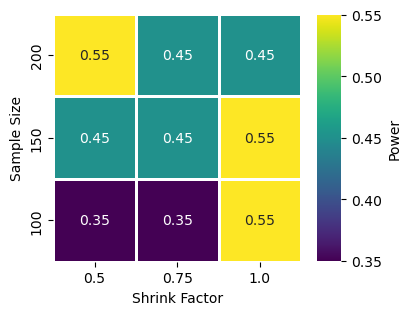

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot as heatmap
heatmat_data = results.pivot(
    index = 'n',
    columns = 'shrink_factor',
    values = 'power'
    )
    

fig, ax = plt.subplots(figsize=(4, 4))

sns.heatmap(
    heatmat_data,
    annot = True,
    fmt = '.2f',
    cmap = 'viridis',
    square = True,
    linewidth = 1,
    cbar_kws = {'label': 'Power', 'shrink': 0.8, 'aspect': 10},
    ax = ax
    )
ax.invert_yaxis()
ax.set_xlabel('Shrink Factor')
ax.set_ylabel('Sample Size')